# SVM lề mềm: ảnh hưởng của tham số C (mục 7.1.2)

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

Cùng dữ liệu với codes/03_soft_margin_C.ipynb

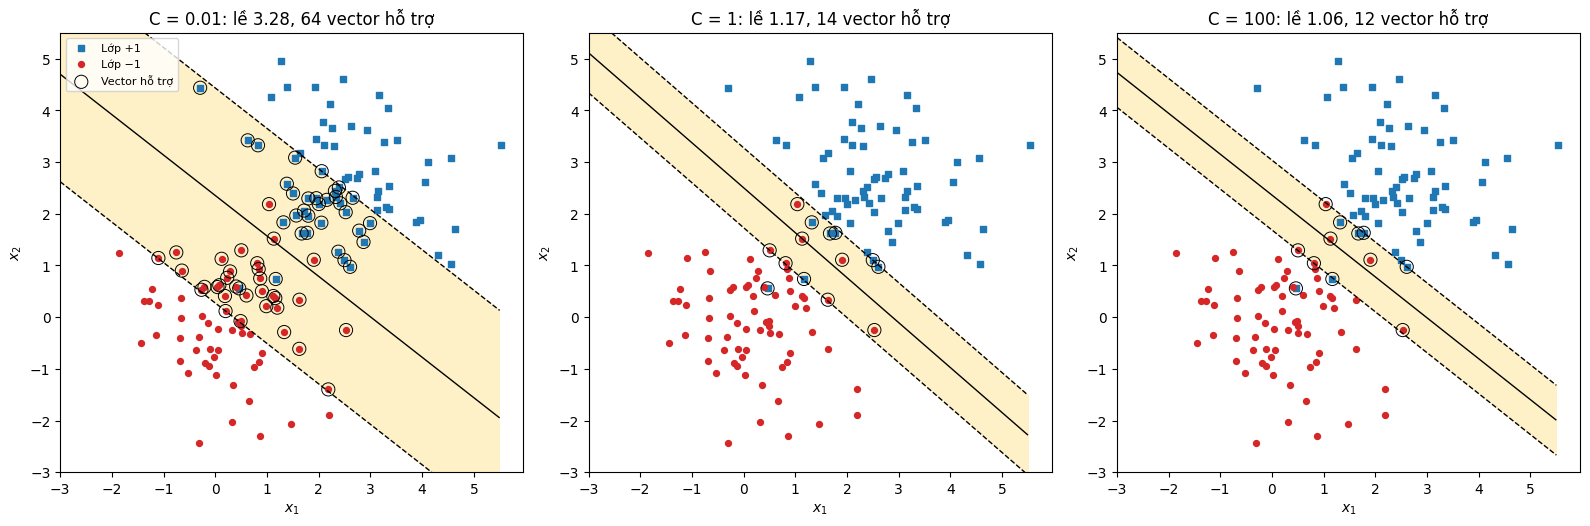

In [2]:
X, y = make_blobs(n_samples=200, centers=[[0, 0], [2.5, 2.5]], cluster_std=1.0, random_state=1)
y = np.where(y == 0, -1, 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

xx, yy = np.meshgrid(np.linspace(-3, 5.5, 300), np.linspace(-3, 5.5, 300))
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, C in zip(axes, [0.01, 1, 100]):
    svm = SVC(kernel='linear', C=C).fit(X_train, y_train)
    zz = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-1, 1], colors=['#FFE8A3'], alpha=0.6)
    ax.contour(xx, yy, zz, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'], linewidths=1)
    ax.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], marker='s', s=18, color='#1F77B4', label='Lớp +1')
    ax.scatter(X_train[y_train == -1, 0], X_train[y_train == -1, 1], s=18, color='#D62728', label='Lớp −1')
    ax.scatter(*svm.support_vectors_.T, s=90, facecolors='none', edgecolors='k', linewidths=0.7, label='Vector hỗ trợ')
    ax.set_title('C = %s: lề %.2f, %d vector hỗ trợ' % (C, 2 / np.linalg.norm(svm.coef_[0]), len(svm.support_)))
    ax.set_aspect('equal'); ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
axes[0].legend(loc='upper left', fontsize=8)
fig.tight_layout()
fig.savefig(IMAGES / 'soft_margin.png', dpi=150)